# MSPE 49600: Data Analytics for Motorsports
## Project 3: Radial Basis Function and Neural Network Modeling

**Student:** Philip Allen  
**Purdue username:** `philipallen04`  
**Course:** MSPE 49600 - Data Analytics for Motorsports  
**Semester:** Fall 2026

### Project scope
Tasks I-V use `ims_setup_project02.csv` to compare Gaussian radial basis function (RBF) and quadratic surrogate models for **mean Sector 3 time** using rear-wing angle and rear ride height. RBF width $\sigma$ and regularization $\lambda$ are selected using leave-one-out cross-validation (LOOCV) on the training setups only.

Task VI is a **separate prediction problem** using `simulated_laptime_data.csv`, with fuel load and tire age as inputs and lap time as the response. ReLU and tanh multilayer perceptrons (MLPs) are compared with a quadratic model using a fixed 75/25 train/test split.

The two datasets describe different problems. Their error values are **not** combined or used to rank models across Tasks I-V and Task VI.

### Reuse and assistance acknowledgment
The setup-level cleaning/grouping pattern in Task I reuses the Project 2 workflow developed for this course, with the Project 3-required output columns. The neural-network workflow is adapted from the **Lecture 16: Introduction to Machine Learning and Neural Networks** CSV example, with the Project 3-specified split, training-only normalization, architecture, solver, regularization, and random seed. OpenAI/ChatGPT was used for code review, debugging, formatting, and verification. The calculations and outputs in this notebook are executed from the supplied course datasets.

In [1]:
# Imports and reproducibility configuration
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.interpolate import RBFInterpolator

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

from IPython.display import display

USERNAME = "philipallen04"
PREFIX = f"{USERNAME}_pr03"
IMS_FILE = Path("ims_setup_project02.csv")
LAPTIME_FILE = Path("simulated_laptime_data.csv")

np.set_printoptions(suppress=True, precision=8)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)
print("IMS source:", IMS_FILE)
print("Lap-time source:", LAPTIME_FILE)

Python: 3.13.16
NumPy: 2.3.5
pandas: 2.2.3
SciPy: 1.17.0
Matplotlib: 3.10.8
scikit-learn: 1.8.0
IMS source: ims_setup_project02.csv
Lap-time source: simulated_laptime_data.csv


# Task I - Data Preparation and Normalization

## 1. Recreate independent setup configurations
The Project 2 cleaning workflow is reused: required columns are converted to numeric values, exact duplicate rows and rows missing required values are removed, and repeated laps are grouped by rear-wing angle and rear ride height. Project 3 retains the mean Sector 3 time, Sector 3 standard deviation, and valid-lap count.

In [2]:
# Load and clean the IMS Project 2 source data
ims_raw = pd.read_csv(IMS_FILE)

print("Raw IMS first five rows:")
display(ims_raw.head())
print("Raw shape:", ims_raw.shape)
print("Missing values:")
display(ims_raw.isna().sum().to_frame("missing_count"))

required_ims = [
    "lap",
    "rear_wing_angle_deg",
    "rear_ride_height_mm",
    "sector_3_time_s",
    "top_speed_kph",
]

ims = ims_raw[required_ims].copy()
for column in required_ims:
    ims[column] = pd.to_numeric(ims[column], errors="coerce")

n_before = len(ims)
n_duplicates = int(ims.duplicated().sum())
ims = ims.drop_duplicates().dropna(subset=required_ims).copy()

print(f"Exact duplicate rows removed: {n_duplicates}")
print(f"Rows removed total: {n_before - len(ims)}")
print(f"Clean lap-level rows: {len(ims)}")

# Recreate Project 3 setup-level table
df_grouped = (
    ims.groupby(["rear_wing_angle_deg", "rear_ride_height_mm"], as_index=False)
       .agg(
           mean_sector_3_time_s=("sector_3_time_s", "mean"),
           std_sector_3_time_s=("sector_3_time_s", "std"),
           valid_laps=("lap", "count"),
       )
       .sort_values(["rear_wing_angle_deg", "rear_ride_height_mm"])
       .reset_index(drop=True)
)

df_grouped.insert(0, "setup_id", np.arange(len(df_grouped), dtype=int))

grouped_file = f"{PREFIX}_grouped.csv"
df_grouped.to_csv(grouped_file, index=False)

print("\nGrouped setup table:")
display(df_grouped)
print("Unique setups:", len(df_grouped))
print("Saved:", grouped_file)

Raw IMS first five rows:


,lap,rear_wing_angle_deg,rear_ride_height_mm,sector_3_time_s,top_speed_kph
0,1,5,35,33.0949,286.761
1,2,5,35,32.9325,287.079
2,3,5,35,33.0858,287.261
3,4,5,35,33.0472,287.059
4,5,5,35,33.0534,287.463


Raw shape: (135, 5)
Missing values:


,missing_count
lap,0
rear_wing_angle_deg,0
rear_ride_height_mm,0
sector_3_time_s,0
top_speed_kph,0


Exact duplicate rows removed: 0
Rows removed total: 0
Clean lap-level rows: 135

Grouped setup table:


,setup_id,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,valid_laps
0,0,5,35,33.04276,0.064925,5
1,1,5,40,32.85104,0.104126,5
2,2,5,45,32.99286,0.022043,5
3,3,6,35,32.51308,0.053101,5
4,4,6,40,32.38096,0.050323,5
5,5,6,45,32.44690,0.077138,5
6,6,7,35,32.03248,0.035651,5
7,7,7,40,31.86244,0.059775,5
8,8,7,45,32.01484,0.053106,5
9,9,8,35,31.68490,0.054910,5


Unique setups: 27
Saved: philipallen04_pr03_grouped.csv


## 2. Setup-level train/test split
The split is performed **after grouping**. If individual repeated laps from the same physical setup were split between training and test data, the model could see the same wing/ride-height configuration during fitting and evaluation, causing data leakage. Keeping the repeated laps together produces an independent test of prediction at held-out setup configurations.

In [3]:
# Sort/reset is already enforced above; split independent setups
# random_state=42 and test_size=0.25 are fixed by the project.
df_train, df_test = train_test_split(
    df_grouped,
    test_size=0.25,
    random_state=42,
)

input_columns = ["rear_wing_angle_deg", "rear_ride_height_mm"]
X_train = df_train[input_columns].to_numpy(dtype=float)
X_test = df_test[input_columns].to_numpy(dtype=float)
y_train = df_train["mean_sector_3_time_s"].to_numpy(dtype=float)
y_test = df_test["mean_sector_3_time_s"].to_numpy(dtype=float)

print("Training setups:", len(df_train))
print("Test setups:", len(df_test))
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Training setups: 20
Test setups: 7
X_train shape: (20, 2)
X_test shape: (7, 2)
y_train shape: (20,)
y_test shape: (7,)


## 3-4. Normalize the physical inputs using fixed Project 2 design bounds
The required fixed domain is **5-13 deg rear-wing angle** and **35-45 mm rear ride height**. These bounds are verified against the supplied dataset and then held fixed for training, test, LOOCV, and plotting. The response is not normalized.

$$
z_j = \frac{x_j-l_j}{u_j-l_j}
$$

In [4]:
# Fixed design-domain bounds required by Project 3
LOWER_BOUNDS = np.array([5.0, 35.0])
UPPER_BOUNDS = np.array([13.0, 45.0])

observed_min = df_grouped[input_columns].min().to_numpy(dtype=float)
observed_max = df_grouped[input_columns].max().to_numpy(dtype=float)

print("Observed minimum:", observed_min)
print("Observed maximum:", observed_max)
print("Prescribed lower bounds:", LOWER_BOUNDS)
print("Prescribed upper bounds:", UPPER_BOUNDS)

assert np.allclose(observed_min, LOWER_BOUNDS)
assert np.allclose(observed_max, UPPER_BOUNDS)

def normalize_ims(X):
    X = np.asarray(X, dtype=float)
    return (X - LOWER_BOUNDS) / (UPPER_BOUNDS - LOWER_BOUNDS)

X_train_n = normalize_ims(X_train)
X_test_n = normalize_ims(X_test)

print("Normalized training range by column:")
print("min:", X_train_n.min(axis=0))
print("max:", X_train_n.max(axis=0))

Observed minimum: [ 5. 35.]
Observed maximum: [13. 45.]
Prescribed lower bounds: [ 5. 35.]
Prescribed upper bounds: [13. 45.]
Normalized training range by column:
min: [0. 0.]
max: [1. 1.]


# Task II - Gaussian RBF Model

The model uses one Gaussian center at every configuration included in the current fit. No polynomial tail or intercept is added.

$$
\phi(\mathbf z,\mathbf c;\sigma)=\exp\left(-\frac{\|\mathbf z-\mathbf c\|_2^2}{2\sigma^2}\right)
$$

$$
(\Phi+\lambda I)\mathbf b=\mathbf y
$$

In [5]:
# 5-6. Required RBF functions

def rbf_matrix(A, B, sigma):
    """Gaussian kernel matrix between every row of A and every row of B."""
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    squared_distances = np.sum((A[:, None, :] - B[None, :, :])**2, axis=2)
    return np.exp(-squared_distances / (2.0 * sigma**2))


def fit_rbf(X, y, sigma, lam):
    """Fit b from (Phi + lam*I)b = y with centers at rows of X."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).ravel()
    Phi = rbf_matrix(X, X, sigma)
    return np.linalg.solve(Phi + lam * np.eye(len(X)), y)


def predict_rbf(X_new, centers, b, sigma):
    """Predict with the same Gaussian centers used in the fit."""
    return rbf_matrix(np.asarray(X_new, dtype=float), np.asarray(centers, dtype=float), sigma) @ np.asarray(b, dtype=float)

sigma_check = 0.20
Phi_train_check = rbf_matrix(X_train_n, X_train_n, sigma_check)
print("Training Gram matrix shape:", Phi_train_check.shape)
print("Maximum |diagonal - 1|:", np.max(np.abs(np.diag(Phi_train_check) - 1.0)))

Training Gram matrix shape: (20, 20)
Maximum |diagonal - 1|: 0.0


## 7. Equivalence check against `scipy.interpolate.RBFInterpolator`
For the required check, the same normalized training data, $\sigma=0.20$, and $\lambda=0.01$ are used. SciPy is configured with `kernel="gaussian"`, `epsilon=1/(sqrt(2)*sigma)`, `smoothing=lam`, and `degree=-1` so its formulation matches the project RBF model.

In [6]:
# SciPy equivalence check at training locations and five additional in-domain points
sigma_equiv = 0.20
lam_equiv = 0.01

b_equiv = fit_rbf(X_train_n, y_train, sigma_equiv, lam_equiv)
scipy_rbf = RBFInterpolator(
    X_train_n,
    y_train,
    kernel="gaussian",
    epsilon=1.0 / (np.sqrt(2.0) * sigma_equiv),
    smoothing=lam_equiv,
    degree=-1,
)

additional_points_physical = np.array([
    [5.5, 36.0],
    [7.5, 37.5],
    [9.5, 39.0],
    [11.5, 42.5],
    [12.5, 44.0],
])
additional_points_n = normalize_ims(additional_points_physical)

check_points = np.vstack([X_train_n, additional_points_n])
ours = predict_rbf(check_points, X_train_n, b_equiv, sigma_equiv)
scipy_predictions = scipy_rbf(check_points)
max_abs_difference = np.max(np.abs(ours - scipy_predictions))

print(f"Maximum absolute prediction difference: {max_abs_difference:.3e} s")
print("Difference <= 1e-6 s:", bool(max_abs_difference <= 1e-6))

equivalence_extra = pd.DataFrame({
    "wing_deg": additional_points_physical[:, 0],
    "ride_height_mm": additional_points_physical[:, 1],
    "our_prediction_s": predict_rbf(additional_points_n, X_train_n, b_equiv, sigma_equiv),
    "scipy_prediction_s": scipy_rbf(additional_points_n),
})
equivalence_extra["abs_difference_s"] = np.abs(equivalence_extra["our_prediction_s"] - equivalence_extra["scipy_prediction_s"])
display(equivalence_extra)

Maximum absolute prediction difference: 1.066e-14 s
Difference <= 1e-6 s: True


,wing_deg,ride_height_mm,our_prediction_s,scipy_prediction_s,abs_difference_s
0,5.5,36.0,29.311215,29.311215,0.000000e+00
1,7.5,37.5,27.027960,27.027960,3.552714e-15
2,9.5,39.0,29.177414,29.177414,3.552714e-15
3,11.5,42.5,26.883974,26.883974,1.065814e-14
4,12.5,44.0,31.165524,31.165524,7.105427e-15


The equivalence difference is at floating-point roundoff scale, far below the required $10^{-6}$ s investigation threshold. This verifies that the custom kernel, regularization placement, and prediction formulation match SciPy for this check.

## 8. Default RBF model
The fitted RBF weights $b_j$ are **model parameters** learned from the training responses. The center locations are fixed by the training input locations. The width $\sigma$ and smoothing/regularization $\lambda$ are **hyperparameters**: they control the model form and are selected using cross-validation rather than solved as the RBF weights.

In [7]:
# Default RBF
sigma_default = 0.20
lam_default = 0.01

b_default = fit_rbf(X_train_n, y_train, sigma_default, lam_default)
yhat_default_train = predict_rbf(X_train_n, X_train_n, b_default, sigma_default)
default_train_rmse = np.sqrt(mean_squared_error(y_train, yhat_default_train))

print(f"Default sigma: {sigma_default}")
print(f"Default lambda: {lam_default}")
print(f"Default training RMSE: {default_train_rmse:.6f} s")

Default sigma: 0.2
Default lambda: 0.01
Default training RMSE: 0.253362 s


# Task III - LOOCV and Hyperparameter Optimization

Hyperparameter optimization here means selecting $\sigma$ and $\lambda$ to minimize **cross-validation prediction error**, not optimizing the physical vehicle setup.

In [8]:
# 9-10. Leave-one-out cross-validation for the custom RBF

def loocv_rbf(X, y, sigma, lam):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).ravel()
    predictions = np.empty(len(y), dtype=float)

    for i in range(len(y)):
        keep = np.arange(len(y)) != i
        b_fold = fit_rbf(X[keep], y[keep], sigma, lam)
        predictions[i] = predict_rbf(X[i:i+1], X[keep], b_fold, sigma)[0]

    residuals = y - predictions
    press = float(np.sum(residuals**2))
    rmse_cv = float(np.sqrt(press / len(y)))
    return predictions, press, rmse_cv

loo_default_predictions, default_press, default_rmse_cv = loocv_rbf(
    X_train_n, y_train, sigma_default, lam_default
)

print(f"Default PRESS: {default_press:.6f} s^2")
print(f"Default RMSE_CV: {default_rmse_cv:.6f} s")
print(f"Default training RMSE: {default_train_rmse:.6f} s")
print(f"RMSE_CV / training RMSE: {default_rmse_cv/default_train_rmse:.2f}")

Default PRESS: 606.205224 s^2
Default RMSE_CV: 5.505476 s
Default training RMSE: 0.253362 s
RMSE_CV / training RMSE: 21.73


The default model has much smaller training error than LOOCV error. This is exactly why training RMSE is not an appropriate criterion for choosing RBF hyperparameters: a model can fit its training locations closely while generalizing poorly when one setup is omitted.

In [9]:
# 11-13. Required 15 x 9 joint hyperparameter search on TRAINING SETUPS ONLY
sigma_values = np.logspace(-1.3, 0, 15)
lam_values = np.logspace(-8, 0, 9)

cv_rows = []
for sigma in sigma_values:
    for lam in lam_values:
        try:
            _, press, rmse_cv = loocv_rbf(X_train_n, y_train, sigma, lam)
            if np.isfinite(press) and np.isfinite(rmse_cv):
                status = "success"
            else:
                press = np.inf
                rmse_cv = np.inf
                status = "failed"
        except (np.linalg.LinAlgError, FloatingPointError, ValueError):
            press = np.inf
            rmse_cv = np.inf
            status = "failed"

        cv_rows.append({
            "sigma": float(sigma),
            "lam": float(lam),
            "PRESS": float(press),
            "RMSE_CV": float(rmse_cv),
            "status": status,
        })

df_cv_search = pd.DataFrame(cv_rows)

successful = df_cv_search.loc[df_cv_search["status"] == "success"].copy()
# Exact-tie rule: lowest RMSE_CV, then larger lambda, then smaller sigma.
successful = successful.sort_values(
    ["RMSE_CV", "lam", "sigma"],
    ascending=[True, False, True],
).reset_index(drop=True)

best_row = successful.iloc[0]
sigma_selected = float(best_row["sigma"])
lam_selected = float(best_row["lam"])
tuned_press = float(best_row["PRESS"])
tuned_rmse_cv = float(best_row["RMSE_CV"])
reduction_pct = 100.0 * (default_rmse_cv - tuned_rmse_cv) / default_rmse_cv

print("Five best successful hyperparameter pairs:")
display(successful.head(5))
print(f"Selected sigma: {sigma_selected:.12g}")
print(f"Selected lambda: {lam_selected:.12g}")
print(f"Selected RMSE_CV: {tuned_rmse_cv:.6f} s")
print(f"RMSE_CV reduction vs default: {reduction_pct:.2f}%")
print("Failed combinations:", int((df_cv_search["status"] == "failed").sum()))

Five best successful hyperparameter pairs:


,sigma,lam,PRESS,RMSE_CV,status
0,0.652057,1.000000e-08,0.126111,0.079407,success
1,0.807501,1.000000e-08,0.150051,0.086617,success
2,0.652057,1.000000e-07,0.154902,0.088006,success
3,1.000000,1.000000e-05,0.162077,0.090021,success
4,0.526537,1.000000e-08,0.171398,0.092574,success


Selected sigma: 0.652057229343
Selected lambda: 1e-08
Selected RMSE_CV: 0.079407 s
RMSE_CV reduction vs default: 98.56%
Failed combinations: 0


## 14. Hyperparameter error surface
The selected $\sigma$ is inside the searched width range, but the selected $\lambda=10^{-8}$ is on the **lower regularization boundary**. Therefore the grid identifies the best tested pair, but it does not prove a continuous optimum lies in the interior of the stated search region. The lowest-error region is concentrated at moderate-to-large $\sigma$ and very small $\lambda$, with several nearby grid points also producing relatively low LOOCV error.

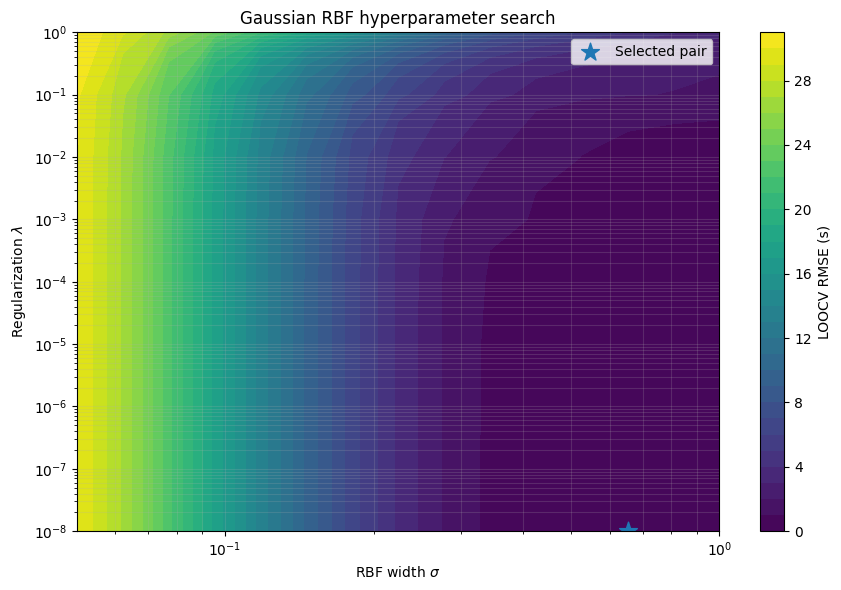

In [10]:
# Figure 1 of 6: RBF LOOCV search contour (embedded in notebook/PDF)
rmse_matrix = (
    df_cv_search.pivot(index="lam", columns="sigma", values="RMSE_CV")
                .reindex(index=lam_values, columns=sigma_values)
                .to_numpy(dtype=float)
)
rmse_masked = np.ma.masked_invalid(np.where(np.isfinite(rmse_matrix), rmse_matrix, np.nan))
SIGMA_GRID, LAM_GRID = np.meshgrid(sigma_values, lam_values)

fig, ax = plt.subplots(figsize=(9, 6))
cf = ax.contourf(SIGMA_GRID, LAM_GRID, rmse_masked, levels=30)
fig.colorbar(cf, ax=ax, label="LOOCV RMSE (s)")
ax.scatter([sigma_selected], [lam_selected], marker="*", s=180, label="Selected pair")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"RBF width $\sigma$")
ax.set_ylabel(r"Regularization $\lambda$")
ax.set_title("Gaussian RBF hyperparameter search")
ax.legend()
ax.grid(alpha=0.2, which="both")
fig.tight_layout()
plt.show()

In [11]:
# 15. LOOCV predictions and residual extremes at the selected pair
loo_tuned_predictions, tuned_press_check, tuned_rmse_cv_check = loocv_rbf(
    X_train_n, y_train, sigma_selected, lam_selected
)
assert np.isclose(tuned_press_check, tuned_press)
assert np.isclose(tuned_rmse_cv_check, tuned_rmse_cv)

# Preserve train_test_split order so each prediction aligns with its held-out fold.
df_loo = df_train[["setup_id", "rear_wing_angle_deg", "rear_ride_height_mm"]].reset_index(drop=True).copy()
df_loo["actual_time_s"] = y_train
df_loo["predicted_time_s"] = loo_tuned_predictions
df_loo["residual_s"] = df_loo["actual_time_s"] - df_loo["predicted_time_s"]
df_loo["abs_residual_s"] = df_loo["residual_s"].abs()

print("Selected-pair LOOCV predictions:")
display(df_loo.drop(columns="abs_residual_s"))

largest_loo = df_loo.loc[df_loo["abs_residual_s"].idxmax()]
smallest_loo = df_loo.loc[df_loo["abs_residual_s"].idxmin()]

print("Largest absolute LOOCV residual:")
display(largest_loo.to_frame().T)
print("Smallest absolute LOOCV residual:")
display(smallest_loo.to_frame().T)

Selected-pair LOOCV predictions:


,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s
0,17,10,45,31.44488,31.440167,0.004713
1,12,9,35,31.44076,31.452658,-0.011898
2,24,13,35,31.59024,31.366482,0.223758
3,1,5,40,32.85104,33.030382,-0.179342
4,4,6,40,32.38096,32.336081,0.044879
5,5,6,45,32.44690,32.410609,0.036291
6,2,5,45,32.99286,33.047647,-0.054787
7,15,10,35,31.32624,31.316919,0.009321
8,22,12,40,31.35834,31.308303,0.050037
9,3,6,35,32.51308,32.576898,-0.063818


Largest absolute LOOCV residual:


,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s,abs_residual_s
2,24.0,13.0,35.0,31.59024,31.366482,0.223758,0.223758


Smallest absolute LOOCV residual:


,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s,abs_residual_s
0,17.0,10.0,45.0,31.44488,31.440167,0.004713,0.004713


# Task IV - Model Comparison and Held-Out Test Evaluation

## 16. Quadratic reference model
The quadratic reference uses the same normalized input coordinates and the six columns $[1,z_1,z_2,z_1^2,z_2^2,z_1z_2]$. Its coefficients are refit in every LOOCV fold.

In [12]:
# Quadratic reference functions

def quadratic_design_matrix(X):
    X = np.asarray(X, dtype=float)
    z1 = X[:, 0]
    z2 = X[:, 1]
    return np.column_stack([
        np.ones(len(X)),
        z1,
        z2,
        z1**2,
        z2**2,
        z1*z2,
    ])


def fit_quadratic(X, y):
    return np.linalg.pinv(quadratic_design_matrix(X)) @ np.asarray(y, dtype=float).ravel()


def predict_quadratic(X, beta):
    return quadratic_design_matrix(X) @ np.asarray(beta, dtype=float)


def loocv_quadratic(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).ravel()
    predictions = np.empty(len(y), dtype=float)
    for i in range(len(y)):
        keep = np.arange(len(y)) != i
        beta_fold = fit_quadratic(X[keep], y[keep])
        predictions[i] = predict_quadratic(X[i:i+1], beta_fold)[0]
    residuals = y - predictions
    press = float(np.sum(residuals**2))
    rmse_cv = float(np.sqrt(press / len(y)))
    return predictions, press, rmse_cv

quad_loo_predictions, quad_press, quad_rmse_cv = loocv_quadratic(X_train_n, y_train)
print(f"Quadratic LOOCV PRESS: {quad_press:.6f} s^2")
print(f"Quadratic LOOCV RMSE: {quad_rmse_cv:.6f} s")

Quadratic LOOCV PRESS: 0.014076 s^2
Quadratic LOOCV RMSE: 0.026529 s


## 17. Pre-test model selection comparison
Before looking at held-out test responses, the three training-set LOOCV errors are compared. The hyperparameter search is now frozen: **no test result is used to revise $\sigma$, $\lambda$, or the search range.**

In [13]:
pretest_comparison = pd.DataFrame([
    {"model": "Default RBF", "RMSE_CV_s": default_rmse_cv},
    {"model": "Tuned RBF", "RMSE_CV_s": tuned_rmse_cv},
    {"model": "Quadratic", "RMSE_CV_s": quad_rmse_cv},
]).sort_values("RMSE_CV_s").reset_index(drop=True)

display(pretest_comparison)
print("Lowest pre-test cross-validation error:", pretest_comparison.loc[0, "model"])

,model,RMSE_CV_s
0,Quadratic,0.026529
1,Tuned RBF,0.079407
2,Default RBF,5.505476


Lowest pre-test cross-validation error: Quadratic


In [14]:
# 18. Fit all three models on all training setups and evaluate the SAME held-out setups

def regression_metrics(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }

# Default RBF
b_default = fit_rbf(X_train_n, y_train, sigma_default, lam_default)
default_train_pred = predict_rbf(X_train_n, X_train_n, b_default, sigma_default)
default_test_pred = predict_rbf(X_test_n, X_train_n, b_default, sigma_default)

# Tuned RBF
b_tuned = fit_rbf(X_train_n, y_train, sigma_selected, lam_selected)
tuned_train_pred = predict_rbf(X_train_n, X_train_n, b_tuned, sigma_selected)
tuned_test_pred = predict_rbf(X_test_n, X_train_n, b_tuned, sigma_selected)

# Quadratic
beta_quad = fit_quadratic(X_train_n, y_train)
quad_train_pred = predict_quadratic(X_train_n, beta_quad)
quad_test_pred = predict_quadratic(X_test_n, beta_quad)

validation_rows = []
for model_name, sigma, lam, train_pred, cv_rmse, test_pred in [
    ("Default RBF", sigma_default, lam_default, default_train_pred, default_rmse_cv, default_test_pred),
    ("Tuned RBF", sigma_selected, lam_selected, tuned_train_pred, tuned_rmse_cv, tuned_test_pred),
    ("Quadratic", np.nan, np.nan, quad_train_pred, quad_rmse_cv, quad_test_pred),
]:
    test_m = regression_metrics(y_test, test_pred)
    validation_rows.append({
        "model": model_name,
        "sigma": sigma,
        "lam": lam,
        "train_RMSE_s": float(np.sqrt(mean_squared_error(y_train, train_pred))),
        "RMSE_CV_s": cv_rmse,
        "test_RMSE_s": test_m["RMSE"],
        "test_MAE_s": test_m["MAE"],
        "test_R2": test_m["R2"],
    })

df_validation = pd.DataFrame(validation_rows)
print("Model validation table:")
display(df_validation)

Model validation table:


,model,sigma,lam,train_RMSE_s,RMSE_CV_s,test_RMSE_s,test_MAE_s,test_R2
0,Default RBF,0.200000,1.000000e-02,0.253362,5.505476,3.169248,2.231456,-29.154571
1,Tuned RBF,0.652057,1.000000e-08,0.000774,0.079407,0.121868,0.086699,0.955412
2,Quadratic,NaN,NaN,0.019241,0.026529,0.025850,0.018986,0.997994


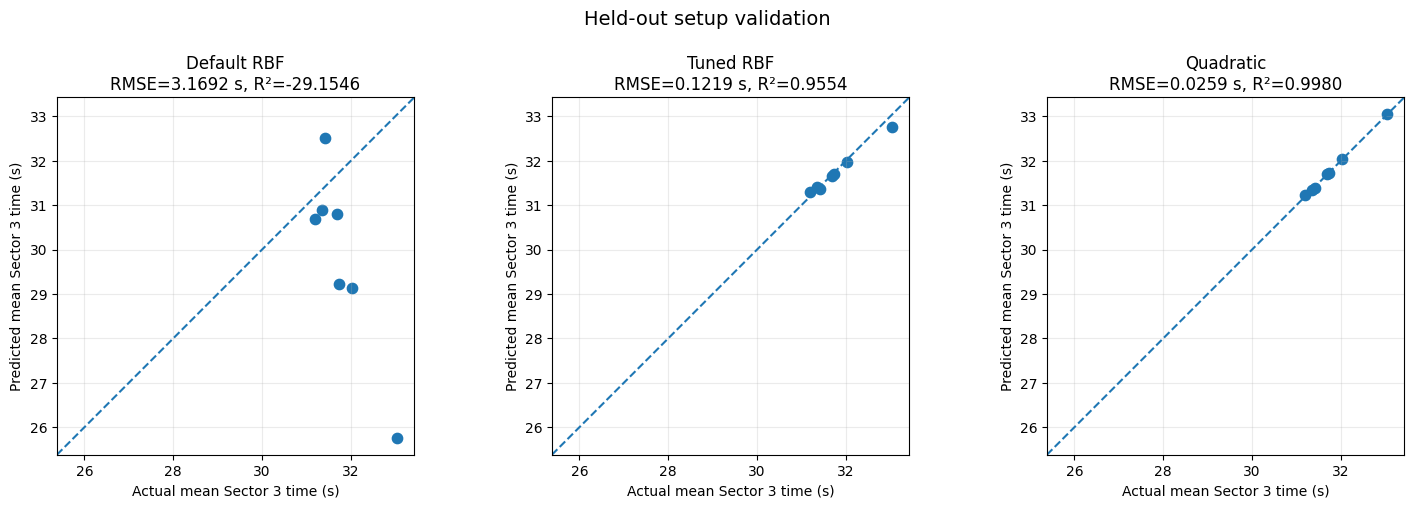

In [15]:
# Figure 2 of 6: actual-versus-predicted held-out IMS setups
predictions_for_plot = [
    ("Default RBF", default_test_pred),
    ("Tuned RBF", tuned_test_pred),
    ("Quadratic", quad_test_pred),
]
all_values = np.concatenate([y_test] + [p for _, p in predictions_for_plot])
lo = float(all_values.min())
hi = float(all_values.max())
pad = 0.05 * (hi - lo)
axis_limits = (lo - pad, hi + pad)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (name, pred) in zip(axes, predictions_for_plot):
    row = df_validation.loc[df_validation["model"] == name].iloc[0]
    ax.scatter(y_test, pred, s=55)
    ax.plot(axis_limits, axis_limits, linestyle="--")
    ax.set_xlim(axis_limits)
    ax.set_ylim(axis_limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Actual mean Sector 3 time (s)")
    ax.set_ylabel("Predicted mean Sector 3 time (s)")
    ax.set_title(f"{name}\nRMSE={row.test_RMSE_s:.4f} s, R²={row.test_R2:.4f}")
    ax.grid(alpha=0.25)
fig.suptitle("Held-out setup validation", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()

## 20. Interpretation of the comparison
Tuning dramatically improves the Gaussian RBF relative to the default settings: its LOOCV RMSE drops from roughly 5.51 s to about 0.079 s, and its held-out test RMSE is also far smaller than the default RBF. However, tuning does **not** make the RBF the best model automatically. The quadratic reference has the lowest training-set LOOCV RMSE and also the lowest held-out test RMSE, MAE, and highest test $R^2$ for this split.

The cross-validation ranking and test ranking therefore agree: the quadratic model ranks first, the tuned RBF second, and the default RBF third. The numerical values of test error and minimum LOOCV error are not expected to match exactly because they are based on different held-out observations. LOOCV repeatedly predicts one omitted training setup at a time, while the test metrics use seven configurations that were completely reserved from model and hyperparameter selection. With only 27 setup means, which particular configurations land in each evaluation set can noticeably change the error.

# Task V - Response Surfaces and Observation Influence

## 21. Final all-data tuned RBF surface
Only after the held-out test results are recorded is the tuned RBF refit on all 27 grouped configurations. This produces a final descriptive response surface but leaves **no independent test set** for that all-data refit.

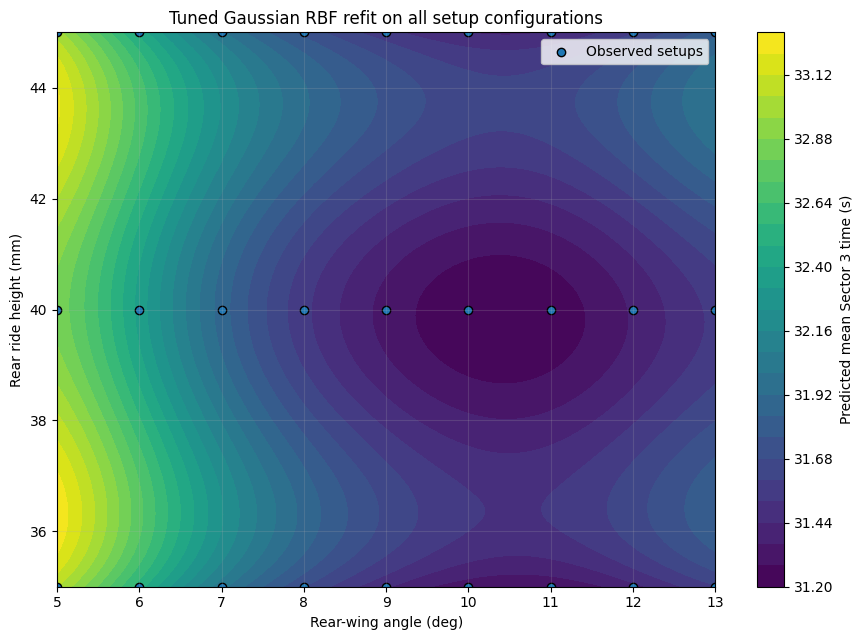

In [16]:
# Physical 101 x 101 IMS plotting grid
wing_grid = np.linspace(LOWER_BOUNDS[0], UPPER_BOUNDS[0], 101)
ride_grid = np.linspace(LOWER_BOUNDS[1], UPPER_BOUNDS[1], 101)
WING_MESH, RIDE_MESH = np.meshgrid(wing_grid, ride_grid)
X_grid_ims = np.column_stack([WING_MESH.ravel(), RIDE_MESH.ravel()])
X_grid_ims_n = normalize_ims(X_grid_ims)

X_all = df_grouped[input_columns].to_numpy(dtype=float)
y_all = df_grouped["mean_sector_3_time_s"].to_numpy(dtype=float)
X_all_n = normalize_ims(X_all)

b_all_tuned = fit_rbf(X_all_n, y_all, sigma_selected, lam_selected)
Y_all_surface = predict_rbf(X_grid_ims_n, X_all_n, b_all_tuned, sigma_selected).reshape(WING_MESH.shape)

# Figure 3 of 6: all-data tuned RBF surface
fig, ax = plt.subplots(figsize=(9, 6.5))
cf = ax.contourf(WING_MESH, RIDE_MESH, Y_all_surface, levels=30)
fig.colorbar(cf, ax=ax, label="Predicted mean Sector 3 time (s)")
ax.scatter(X_all[:, 0], X_all[:, 1], marker="o", edgecolor="k", label="Observed setups")
ax.set_xlabel("Rear-wing angle (deg)")
ax.set_ylabel("Rear ride height (mm)")
ax.set_title("Tuned Gaussian RBF refit on all setup configurations")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

/tmp/ipykernel_5026/2137982312.py:50: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


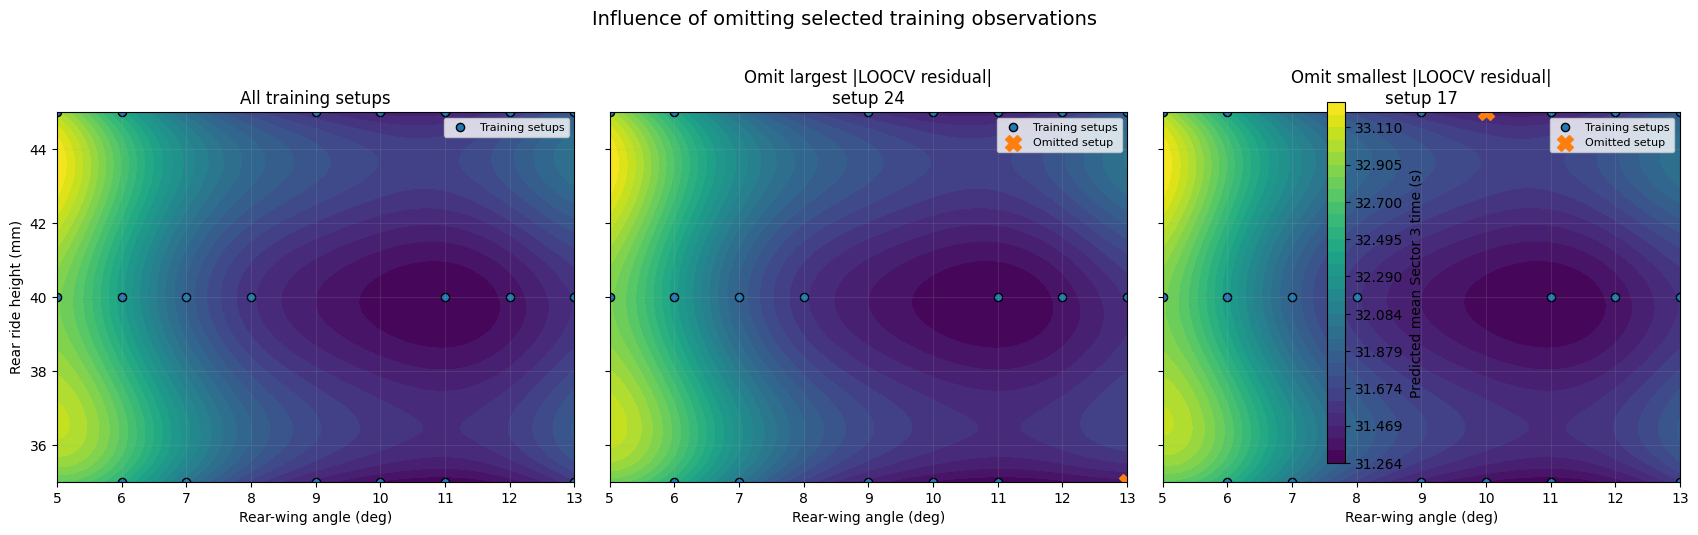

Largest-residual setup omitted in middle panel: 24
Smallest-residual setup omitted in right panel: 17


In [17]:
# 22. Influence surfaces using training data only and the selected hyperparameters
largest_setup_id = int(largest_loo["setup_id"])
smallest_setup_id = int(smallest_loo["setup_id"])

# Establish training arrays in df_train order.
train_meta = df_train[["setup_id", "rear_wing_angle_deg", "rear_ride_height_mm"]].reset_index(drop=True)


def fit_surface_after_omission(omit_setup_id=None):
    if omit_setup_id is None:
        keep = np.ones(len(train_meta), dtype=bool)
    else:
        keep = train_meta["setup_id"].to_numpy() != omit_setup_id
    centers = X_train_n[keep]
    yy = y_train[keep]
    b = fit_rbf(centers, yy, sigma_selected, lam_selected)
    surface = predict_rbf(X_grid_ims_n, centers, b, sigma_selected).reshape(WING_MESH.shape)
    return surface

surface_full_train = fit_surface_after_omission(None)
surface_without_largest = fit_surface_after_omission(largest_setup_id)
surface_without_smallest = fit_surface_after_omission(smallest_setup_id)

shared_min = min(s.min() for s in [surface_full_train, surface_without_largest, surface_without_smallest])
shared_max = max(s.max() for s in [surface_full_train, surface_without_largest, surface_without_smallest])
levels = np.linspace(shared_min, shared_max, 30)

# Figure 4 of 6: three influence panels
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharex=True, sharey=True)
configurations = [
    ("All training setups", surface_full_train, None),
    (f"Omit largest |LOOCV residual|\nsetup {largest_setup_id}", surface_without_largest, largest_setup_id),
    (f"Omit smallest |LOOCV residual|\nsetup {smallest_setup_id}", surface_without_smallest, smallest_setup_id),
]
last_cf = None
for ax, (title, surface, omitted_id) in zip(axes, configurations):
    last_cf = ax.contourf(WING_MESH, RIDE_MESH, surface, levels=levels)
    ax.scatter(X_train[:, 0], X_train[:, 1], marker="o", s=35, edgecolor="k", label="Training setups")
    if omitted_id is not None:
        omitted = train_meta.loc[train_meta["setup_id"] == omitted_id].iloc[0]
        ax.scatter(omitted["rear_wing_angle_deg"], omitted["rear_ride_height_mm"], marker="X", s=130, label="Omitted setup")
    ax.set_title(title)
    ax.set_xlabel("Rear-wing angle (deg)")
    ax.grid(alpha=0.15)
axes[0].set_ylabel("Rear ride height (mm)")
for ax in axes:
    ax.legend(fontsize=8)
fig.colorbar(last_cf, ax=axes, label="Predicted mean Sector 3 time (s)", shrink=0.9)
fig.suptitle("Influence of omitting selected training observations", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()

print("Largest-residual setup omitted in middle panel:", largest_setup_id)
print("Smallest-residual setup omitted in right panel:", smallest_setup_id)

## 23-24. Final RBF discussion and model recommendation

The Gaussian RBF has two key hyperparameters. The width $\sigma$ controls how broadly each training center influences nearby points: a small width creates highly local basis functions, while a larger width produces broader, smoother coupling across the normalized setup space. The regularization $\lambda$ is added directly to the Gram matrix before solving for the RBF weights. Increasing it reduces exact interpolation and generally smooths/stabilizes the fit, while very small values allow the model to track the setup means closely. The weights $b_j$ are fitted parameters; $\sigma$ and $\lambda$ are selected hyperparameters.

Training RMSE is unsuitable for choosing these hyperparameters because a flexible RBF can nearly interpolate the training responses without predicting omitted configurations well. This is visible in the tuned model: its training RMSE is extremely small, while LOOCV remains meaningfully larger. The required hyperparameter contour selects $\sigma\approx0.6521$ and $\lambda=10^{-8}$. The selected $\lambda$ lies on the lower search boundary, so the grid identifies the best tested pair rather than proving that a continuous optimum lies inside the search limits. Several neighboring moderate-width, low-regularization combinations also have low error, but performance deteriorates rapidly for narrow kernels.

The omission panels show that removing the largest-LOOCV-residual setup changes the local response surface more visibly than removing the smallest-residual setup, although the effect is not uniform across the entire domain. A large omitted-point prediction error measures difficulty predicting that observation; it does not imply an equally large change everywhere.

For **Sector 3 prediction**, I recommend the **quadratic model** for this dataset. Its training-set LOOCV RMSE is lower than the tuned RBF's and its independent test RMSE is also substantially lower. Limitations include only 27 unique setups, noise in setup means, a fixed RBF search grid, and possible numerical sensitivity at very small $\lambda$. The all-data RBF surface is descriptive only: after refitting on all configurations there is no independent test set left, and the surface does not verify a physical optimum or the Project 2 top-speed constraint.

# Task VI - Neural Networks with the Separate CSV Lap-Time Dataset

This section follows the structure of the **Lecture 16 CSV MLP example**, but uses the Project 3-required 75/25 split, training-only normalization, fixed `(20, 20)` network architecture, `lbfgs` solver, `alpha=0.1`, `max_iter=5000`, and `random_state=1`. No MLP hyperparameter search or additional LOOCV is performed.

In [18]:
# 25. Load the separate 100-observation lap-time dataset
lap_df = pd.read_csv(LAPTIME_FILE)
lap_df = lap_df.copy()
lap_df["row_id"] = lap_df.index.astype(int)

print("First five rows:")
display(lap_df.head())
print("Description:")
display(lap_df.describe())
print("Row count:", len(lap_df))
print("Missing-value counts:")
display(lap_df.isna().sum().to_frame("missing_count"))

lap_features = ["fuel_kg", "tire_age_laps"]
assert list(lap_df.columns[:3]) == ["fuel_kg", "tire_age_laps", "time_s"]
assert len(lap_df) == 100

First five rows:


,fuel_kg,tire_age_laps,time_s,row_id
0,22.189146,7.846392,64.810266,0
1,29.207419,5.174721,65.917722,1
2,16.306554,10.407846,65.457985,2
3,29.178391,7.585621,65.778464,3
4,18.989303,9.723292,65.446376,4


Description:


,fuel_kg,tire_age_laps,time_s,row_id
count,100.000000,100.000000,100.000000,100.000000
mean,22.209104,6.037854,65.101500,49.500000
std,4.615793,3.263998,0.964395,29.011492
min,14.093194,0.200674,63.108675,0.000000
25%,18.199190,3.511454,64.372019,24.750000
50%,22.223122,5.598018,65.020940,49.500000
75%,26.468585,9.008879,65.619956,74.250000
max,29.691795,11.988311,67.987389,99.000000


Row count: 100
Missing-value counts:


,missing_count
fuel_kg,0
tire_age_laps,0
time_s,0
row_id,0


In [19]:
# 26. Required 75/25 split; compute normalization bounds from TRAINING observations only
lap_train, lap_test = train_test_split(
    lap_df,
    test_size=0.25,
    random_state=42,
)

X_lap_train = lap_train[lap_features].to_numpy(dtype=float)
X_lap_test = lap_test[lap_features].to_numpy(dtype=float)
y_lap_train = lap_train["time_s"].to_numpy(dtype=float)
y_lap_test = lap_test["time_s"].to_numpy(dtype=float)

lap_min = X_lap_train.min(axis=0)
lap_max = X_lap_train.max(axis=0)


def normalize_laptime_inputs(X):
    X = np.asarray(X, dtype=float)
    return (X - lap_min) / (lap_max - lap_min)

X_lap_train_n = normalize_laptime_inputs(X_lap_train)
X_lap_test_n = normalize_laptime_inputs(X_lap_test)

print("Training observations:", len(lap_train))
print("Test observations:", len(lap_test))
print(f"Training fuel bounds: {lap_min[0]:.6f} to {lap_max[0]:.6f} kg")
print(f"Training tire-age bounds: {lap_min[1]:.6f} to {lap_max[1]:.6f} laps")
print("Normalized test minima (not clipped):", X_lap_test_n.min(axis=0))
print("Normalized test maxima (not clipped):", X_lap_test_n.max(axis=0))

Training observations: 75
Test observations: 25
Training fuel bounds: 14.093194 to 29.691795 kg
Training tire-age bounds: 0.201927 to 11.988311 laps
Normalized test minima (not clipped): [ 0.05797954 -0.00010636]
Normalized test maxima (not clipped): [0.98249451 0.98899715]


## 27-28. Fixed ReLU and tanh MLPs plus quadratic reference
`alpha=0.1` is the MLP's L2 weight penalty. It is unrelated to the RBF smoothing parameter $\lambda$. Warnings are captured and printed rather than silently suppressed.

In [20]:
# Fit fixed MLP models and report convergence information
lap_models = {}
lap_warning_messages = {}

for activation in ["relu", "tanh"]:
    model = MLPRegressor(
        hidden_layer_sizes=(20, 20),
        activation=activation,
        solver="lbfgs",
        alpha=0.1,
        max_iter=5000,
        random_state=1,
    )
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model.fit(X_lap_train_n, y_lap_train)

    convergence_messages = [
        str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)
    ]
    lap_models[activation] = model
    lap_warning_messages[activation] = convergence_messages

    print(f"{activation} n_iter_: {model.n_iter_}")
    if convergence_messages:
        print(f"{activation} convergence warning(s):")
        for message in convergence_messages:
            print(" -", message)
    else:
        print(f"{activation} convergence warning: none")

# Quadratic model on the same normalized training observations
beta_lap_quad = fit_quadratic(X_lap_train_n, y_lap_train)

relu n_iter_: 328
relu convergence warning: none


tanh n_iter_: 2197
tanh convergence warning: none


In [21]:
# Evaluate all three training-fitted models on the same 25 test observations
relu_model = lap_models["relu"]
tanh_model = lap_models["tanh"]

lap_predictions = {
    "ReLU MLP": {
        "train": relu_model.predict(X_lap_train_n),
        "test": relu_model.predict(X_lap_test_n),
    },
    "tanh MLP": {
        "train": tanh_model.predict(X_lap_train_n),
        "test": tanh_model.predict(X_lap_test_n),
    },
    "Quadratic": {
        "train": predict_quadratic(X_lap_train_n, beta_lap_quad),
        "test": predict_quadratic(X_lap_test_n, beta_lap_quad),
    },
}

lap_metric_rows = []
for model_name, activation, n_iter in [
    ("ReLU MLP", "relu", relu_model.n_iter_),
    ("tanh MLP", "tanh", tanh_model.n_iter_),
    ("Quadratic", np.nan, np.nan),
]:
    train_pred = lap_predictions[model_name]["train"]
    test_pred = lap_predictions[model_name]["test"]
    test_m = regression_metrics(y_lap_test, test_pred)
    lap_metric_rows.append({
        "model": model_name,
        "activation": activation,
        "train_RMSE_s": float(np.sqrt(mean_squared_error(y_lap_train, train_pred))),
        "test_RMSE_s": test_m["RMSE"],
        "test_MAE_s": test_m["MAE"],
        "test_R2": test_m["R2"],
        "n_iter": n_iter,
    })

df_laptime_metrics = pd.DataFrame(lap_metric_rows)
metrics_file = f"{PREFIX}_laptime_metrics.csv"
df_laptime_metrics.to_csv(metrics_file, index=False)

print("Lap-time model metrics:")
display(df_laptime_metrics)
print("Saved:", metrics_file)

Lap-time model metrics:


,model,activation,train_RMSE_s,test_RMSE_s,test_MAE_s,test_R2,n_iter
0,ReLU MLP,relu,0.431688,0.559775,0.425405,0.683070,328.0
1,tanh MLP,tanh,0.187992,0.207254,0.171928,0.956555,2197.0
2,Quadratic,NaN,0.535688,0.590557,0.431262,0.647255,NaN


Saved: philipallen04_pr03_laptime_metrics.csv


In [22]:
# 29. Save one prediction for every original observation using training-fitted models only
X_lap_all = lap_df[lap_features].to_numpy(dtype=float)
X_lap_all_n = normalize_laptime_inputs(X_lap_all)

relu_all_pred = relu_model.predict(X_lap_all_n)
tanh_all_pred = tanh_model.predict(X_lap_all_n)
quad_all_pred = predict_quadratic(X_lap_all_n, beta_lap_quad)

test_row_ids = set(lap_test["row_id"].astype(int).tolist())
split_labels = ["test" if int(row_id) in test_row_ids else "train" for row_id in lap_df["row_id"]]

df_laptime_predictions = pd.DataFrame({
    "row_id": lap_df["row_id"].astype(int),
    "split": split_labels,
    "fuel_kg": lap_df["fuel_kg"],
    "tire_age_laps": lap_df["tire_age_laps"],
    "actual_time_s": lap_df["time_s"],
    "relu_prediction_s": relu_all_pred,
    "tanh_prediction_s": tanh_all_pred,
    "quadratic_prediction_s": quad_all_pred,
})

predictions_file = f"{PREFIX}_laptime_predictions.csv"
df_laptime_predictions.to_csv(predictions_file, index=False)
print("Saved:", predictions_file)
print("Prediction rows:", len(df_laptime_predictions))
display(df_laptime_predictions.head())

Saved: philipallen04_pr03_laptime_predictions.csv
Prediction rows: 100


,row_id,split,fuel_kg,tire_age_laps,actual_time_s,relu_prediction_s,tanh_prediction_s,quadratic_prediction_s
0,0,test,22.189146,7.846392,64.810266,64.596134,64.793894,64.709888
1,1,train,29.207419,5.174721,65.917722,66.221713,65.914650,66.117398
2,2,train,16.306554,10.407846,65.457985,64.953340,65.410496,64.981211
3,3,train,29.178391,7.585621,65.778464,65.825230,65.925719,66.025416
4,4,test,18.989303,9.723292,65.446376,64.589696,65.006381,64.534772


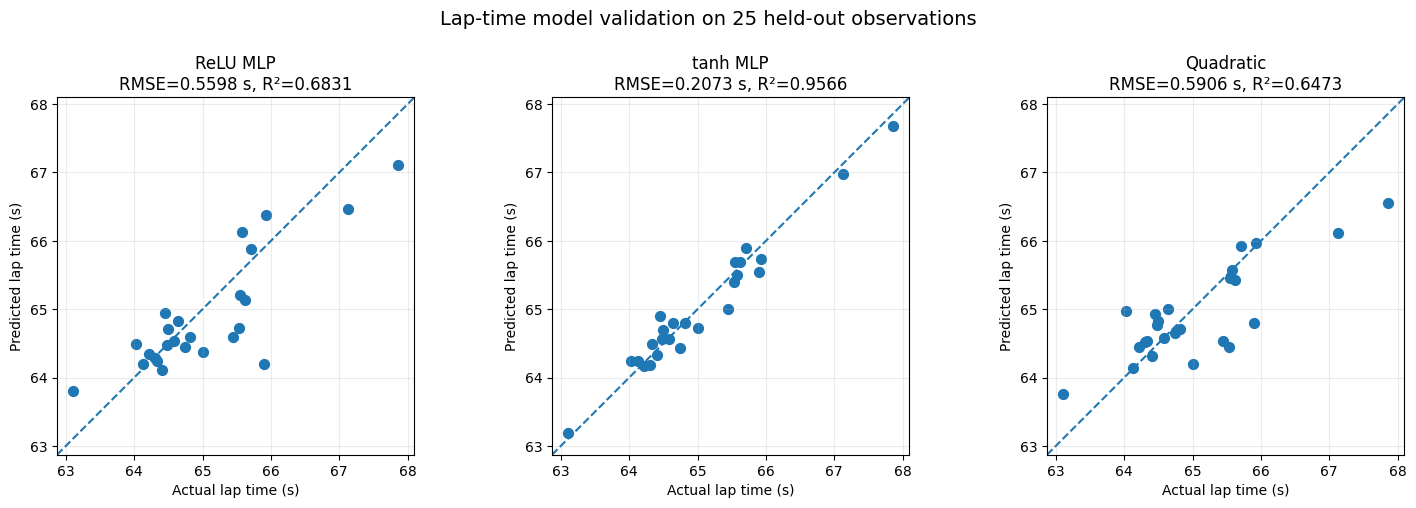

Saved: philipallen04_pr03_laptime_validation.png


In [23]:
# Figure 5 of 6: required lap-time actual-vs-predicted PNG, TEST observations only
lap_plot_models = [
    ("ReLU MLP", lap_predictions["ReLU MLP"]["test"]),
    ("tanh MLP", lap_predictions["tanh MLP"]["test"]),
    ("Quadratic", lap_predictions["Quadratic"]["test"]),
]
all_lap_values = np.concatenate([y_lap_test] + [p for _, p in lap_plot_models])
lap_lo, lap_hi = float(all_lap_values.min()), float(all_lap_values.max())
lap_pad = 0.05 * (lap_hi - lap_lo)
lap_limits = (lap_lo - lap_pad, lap_hi + lap_pad)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (name, pred) in zip(axes, lap_plot_models):
    row = df_laptime_metrics.loc[df_laptime_metrics["model"] == name].iloc[0]
    ax.scatter(y_lap_test, pred, s=50)
    ax.plot(lap_limits, lap_limits, linestyle="--")
    ax.set_xlim(lap_limits)
    ax.set_ylim(lap_limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Actual lap time (s)")
    ax.set_ylabel("Predicted lap time (s)")
    ax.set_title(f"{name}\nRMSE={row.test_RMSE_s:.4f} s, R²={row.test_R2:.4f}")
    ax.grid(alpha=0.25)
fig.suptitle("Lap-time model validation on 25 held-out observations", y=1.02, fontsize=14)
fig.tight_layout()

laptime_validation_png = f"{PREFIX}_laptime_validation.png"
fig.savefig(laptime_validation_png, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", laptime_validation_png)

/tmp/ipykernel_5026/37812395.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


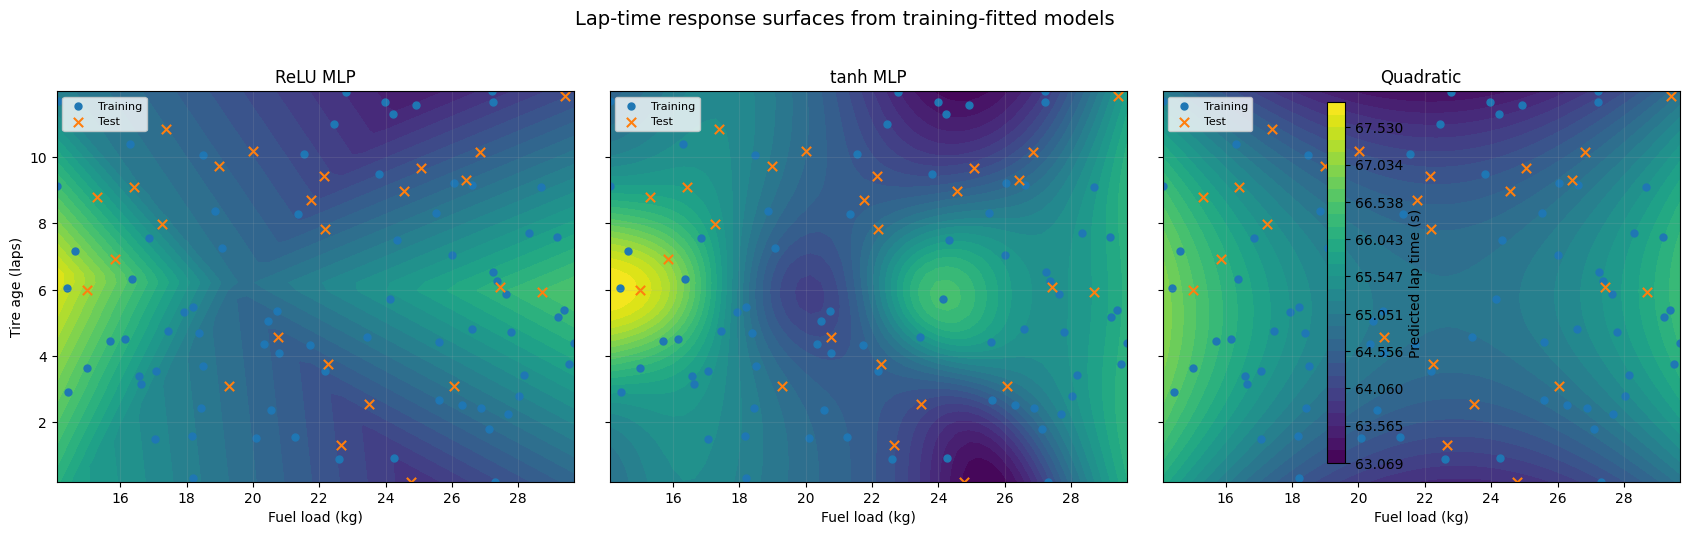

Saved: philipallen04_pr03_laptime_surfaces.png


In [24]:
# 30. Required 50 x 50 physical meshgrid -> column_stack -> training-bound normalization -> predict -> reshape
fuel_grid = np.linspace(lap_df["fuel_kg"].min(), lap_df["fuel_kg"].max(), 50)
tire_grid = np.linspace(lap_df["tire_age_laps"].min(), lap_df["tire_age_laps"].max(), 50)
FUEL_MESH, TIRE_MESH = np.meshgrid(fuel_grid, tire_grid)
X_grid_lap = np.column_stack([FUEL_MESH.ravel(), TIRE_MESH.ravel()])
X_grid_lap_n = normalize_laptime_inputs(X_grid_lap)

relu_surface = relu_model.predict(X_grid_lap_n).reshape(FUEL_MESH.shape)
tanh_surface = tanh_model.predict(X_grid_lap_n).reshape(FUEL_MESH.shape)
quad_surface = predict_quadratic(X_grid_lap_n, beta_lap_quad).reshape(FUEL_MESH.shape)

surface_min = min(relu_surface.min(), tanh_surface.min(), quad_surface.min())
surface_max = max(relu_surface.max(), tanh_surface.max(), quad_surface.max())
surface_levels = np.linspace(surface_min, surface_max, 30)

# Figure 6 of 6: required lap-time surfaces PNG
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharex=True, sharey=True)
last_cf = None
for ax, (name, surface) in zip(
    axes,
    [("ReLU MLP", relu_surface), ("tanh MLP", tanh_surface), ("Quadratic", quad_surface)],
):
    last_cf = ax.contourf(FUEL_MESH, TIRE_MESH, surface, levels=surface_levels)
    ax.scatter(lap_train["fuel_kg"], lap_train["tire_age_laps"], marker="o", s=25, label="Training")
    ax.scatter(lap_test["fuel_kg"], lap_test["tire_age_laps"], marker="x", s=45, label="Test")
    ax.set_xlabel("Fuel load (kg)")
    ax.set_title(name)
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Tire age (laps)")
fig.colorbar(last_cf, ax=axes, label="Predicted lap time (s)", shrink=0.9)
fig.suptitle("Lap-time response surfaces from training-fitted models", y=1.02, fontsize=14)
fig.tight_layout()

laptime_surfaces_png = f"{PREFIX}_laptime_surfaces.png"
fig.savefig(laptime_surfaces_png, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", laptime_surfaces_png)

## 31. Neural-network interpretation

A ReLU neuron applies $\max(0,z)$ to its weighted input, so a network built from ReLU units creates a flexible piecewise-linear mapping. The tanh activation maps its weighted input smoothly into the interval $(-1,1)$, producing a differentiable nonlinear response. With the architecture and training settings fixed by this project, the resulting surfaces reflect both the activation function and the weights/biases learned from the 75 training observations. In these results, the ReLU surface shows more piecewise changes in slope, while the tanh surface changes more smoothly across fuel load and tire age. The quadratic reference is also smooth but is restricted to a global second-order polynomial form.

On the 25 held-out observations, the **tanh MLP has the lowest test RMSE**, followed by the quadratic model and then the ReLU MLP. Thus, in this dataset the smoother tanh network also predicts better on the specified test split. That is evidence for this particular split and fixed settings, not a universal claim that tanh or neural networks are always superior.

The network **weights and biases** are learned model parameters. The `(20,20)` architecture, activation choice, `lbfgs` solver, `alpha=0.1`, `max_iter=5000`, and random seed are fixed hyperparameters for this exercise. A single 75/25 split gives only one estimate of generalization, and predictions are less trustworthy in sparsely sampled parts of the fuel/tire-age plane, especially where plotting points extend outside the training normalization range. No model was retuned in response to test-set performance.

# Final Reproducibility Check and Summary

The required repository deliverables are generated with relative data paths. Tasks I-V and Task VI remain separate analyses. The RBF hyperparameters are selected without using the IMS test responses, and the lap-time MLPs are trained only on the 75 training observations.

In [25]:
# Summary values and required output checks
best_laptime_model = df_laptime_metrics.sort_values("test_RMSE_s").iloc[0]

print("FINAL SUMMARY")
print(f"Selected RBF sigma: {sigma_selected:.12g}")
print(f"Selected RBF lambda: {lam_selected:.12g}")
print(f"Tuned RBF LOOCV RMSE: {tuned_rmse_cv:.6f} s")
print(f"Quadratic LOOCV RMSE: {quad_rmse_cv:.6f} s")
print("Recommended IMS prediction model: Quadratic")
print(f"Best lap-time test model: {best_laptime_model['model']} (RMSE={best_laptime_model['test_RMSE_s']:.6f} s)")

required_generated = [
    f"{PREFIX}_grouped.csv",
    f"{PREFIX}_laptime_metrics.csv",
    f"{PREFIX}_laptime_predictions.csv",
    f"{PREFIX}_laptime_validation.png",
    f"{PREFIX}_laptime_surfaces.png",
]

FINAL SUMMARY
Selected RBF sigma: 0.652057229343
Selected RBF lambda: 1e-08
Tuned RBF LOOCV RMSE: 0.079407 s
Quadratic LOOCV RMSE: 0.026529 s
Recommended IMS prediction model: Quadratic
Best lap-time test model: tanh MLP (RMSE=0.207254 s)
